# 04 — HistGradientBoosting
### Telco Customer Churn Prediction

Gradient boosting is usually the strongest learner on tabular data. HistGradientBoosting is scikit-learn's own fast implementation, so it needs no extra dependency.

**Shared protocol** (identical in notebooks 01–06):
- Same training set (3,944 customers) and same 5 stratified folds (`random_state = 34`).
- Same preprocessing (`FINAL_PREP_CONFIG` from notebook 00): binary add-ons, one-hot `InternetService` and `Contract`, binary `Dependents`/`PaperlessBilling`, standardised `log(1 + tenure)` and `MonthlyCharges`.
- Same tuning procedure: **nested cross-validation** (inner 5-fold grid search, outer 5-fold evaluation), scored by PR-AUC.
- Unweighted classes; class imbalance is handled at the decision threshold (notebook 08) and examined in notebook 07.
- The test set is **not used**. The nested out-of-fold predictions saved at the end are used for comparison and threshold selection in notebook 08.

## 1. How the Algorithm Works

Gradient boosting builds trees **sequentially**. Each new shallow tree is fitted to the errors of the current ensemble, i.e. the gradient of the log-loss with respect to the current predictions. Its contribution is scaled by the `learning_rate` before being added.

The "histogram" variant first bins each numeric feature into at most 255 intervals, which makes split finding fast.

**Bagging vs boosting:**
- bagging (Random Forest) reduces *variance* by averaging independent deep trees;
- boosting reduces *bias* by adding many small trees that correct the remaining errors, so it relies on regularisation (small trees, a small learning rate, a minimum leaf size) to avoid overfitting.

## 2. Relevance, Assumptions and Limitations

- **Relevance:** the most likely algorithm to capture interactions (such as month-to-month × fiber) that Logistic Regression cannot represent.
- **Limitations:**
  - least interpretable of the scikit-learn models;
  - several interacting hyperparameters;
  - can overfit small, noisy datasets.

## 3. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's shared src/ package importable, wherever Jupyter was started
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_preprocessing.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from src.data_preprocessing import FINAL_PREP_CONFIG, RANDOM_STATE, build_pipeline, load_raw_data, split_train_test
from src.evaluation import (cv_scores, final_search, fold_metrics, mean_std_table, nested_summary_row, run_nested_cv,
                            save_results, summarise_cv)
from src.visualization import plot_confusion, plot_permutation_importance, plot_reliability, save_figure, set_style

set_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

df = load_raw_data()                                       # validated raw data (read-only)
X_train, X_test, y_train, y_test = split_train_test(df)   # the project's single stratified 80/20 split
del X_test, y_test                                        # the test set is not used in this notebook
print(f"Training set: {X_train.shape[0]:,} customers, {int(y_train.sum()):,} churners ({y_train.mean():.2%})")
print("Preprocessing configuration (from notebook 00):", FINAL_PREP_CONFIG)

Training set: 3,944 customers, 1,053 churners (26.70%)
Preprocessing configuration (from notebook 00): {'contract': 'onehot', 'addons': 'binary', 'tenure': 'log'}


In [2]:
MODEL_NAME = "HistGradientBoosting"
SLUG = "04_hist_gradient_boosting"
INTERPRETABILITY_RANK = 4  # 1 = most interpretable

## 4. Preprocessing Pipeline

The shared pipeline is used. Scaling and the log transform do not change tree splits, and the binary columns are handled like any numeric feature.

In [3]:
ESTIMATOR = HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE)


pipeline = build_pipeline(ESTIMATOR, **FINAL_PREP_CONFIG)
print("Pipeline steps:", [name for name, _ in pipeline.steps])
print("Transformers:", [(name, cols) for name, _, cols in pipeline.named_steps["preprocess"].transformers])
print("Model:", ESTIMATOR)

Pipeline steps: ['preprocess', 'model']
Transformers: [('binary', ['Dependents', 'PaperlessBilling']), ('addons', ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']), ('internet', ['InternetService']), ('contract', ['Contract']), ('tenure_log', ['tenure']), ('numeric', ['MonthlyCharges'])]
Model: HistGradientBoostingClassifier(max_iter=200, random_state=34)


## 5. Baseline Configuration

The baseline uses scikit-learn's defaults: learning rate 0.1, up to 100 iterations, 31-leaf trees, early stopping only for datasets above 10,000 rows.

In [4]:
BASELINE_ESTIMATOR = HistGradientBoostingClassifier(random_state=RANDOM_STATE)


baseline_raw = cv_scores(build_pipeline(BASELINE_ESTIMATOR, **FINAL_PREP_CONFIG), X_train, y_train)
baseline = summarise_cv(baseline_raw)
display(mean_std_table(pd.DataFrame([baseline], index=["Baseline (5-fold CV, threshold 0.5)"])))
gap = {m: baseline[f"{m} train"] - baseline[f"{m} mean"] for m in ["F1", "ROC-AUC", "PR-AUC"]}
print("Train - validation gap:", {k: round(v, 3) for k, v in gap.items()})

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
"Baseline (5-fold CV, threshold 0.5)",0.780 ± 0.019,0.604 ± 0.045,0.521 ± 0.023,0.559 ± 0.029,0.827 ± 0.017,0.625 ± 0.029


Train - validation gap: {'F1': np.float64(0.218), 'ROC-AUC': np.float64(0.129), 'PR-AUC': np.float64(0.248)}


**Interpretation.**
- With default settings (learning rate 0.1, 31-leaf trees), HistGradientBoosting reaches validation PR-AUC **0.625** and ROC-AUC 0.827.
- Training-fold PR-AUC is 0.248 higher, so the default trees are too large for this dataset and fit noise.

## 6. Hyperparameter Tuning Methodology


Hyperparameters are tuned with **nested cross-validation**:
- the 5 outer folds hold out 20% of the training set in turn;
- on the other 80%, a full grid search with its own inner 5-fold CV chooses the configuration;
- the chosen configuration, refitted on that 80%, predicts the held-out outer fold.

The outer-fold labels never influence tuning, so the resulting out-of-fold (OOF) probabilities are honest estimates of how the *whole hyperparameter-tuning procedure* performs on unseen customers. (The preprocessing configuration was fixed beforehand in notebook 00 using the same training folds; notebook 08, Section 6 shows that re-selecting it inside the nested loop changes the estimate only marginally.) A simpler "tune on everything, then cross-validate" design would reuse the same labels for selection and evaluation, which makes the estimates optimistic.

| Hyperparameter | Values | Role |
|---|---|---|
| `max_iter` | 200 (fixed) | Number of boosting rounds |
| `learning_rate` | 0.01, 0.03, 0.1 | Shrinkage of each tree's contribution (range extended after a first run selected the boundary value) |
| `max_leaf_nodes` | 4, 7, 15 | Complexity of each tree (range extended after a first run selected the boundary value) |
| `min_samples_leaf` | 20, 50 | Minimum customers per leaf |
| `l2_regularization` | 0, 1 | Penalty on leaf values |

In [5]:
PARAM_GRID = {"model__learning_rate": [0.01, 0.03, 0.1], "model__max_leaf_nodes": [4, 7, 15], "model__min_samples_leaf": [20, 50], "model__l2_regularization": [0.0, 1.0]}


n_configurations = int(np.prod([len(v) for v in PARAM_GRID.values()]))
print(f"{n_configurations} configurations x 5 inner folds x 5 outer folds = {n_configurations * 25} fits "
      f"(+ {5} refits) in the nested CV")

36 configurations x 5 inner folds x 5 outer folds = 900 fits (+ 5 refits) in the nested CV


## 7. Nested Cross-Validation Results

In [6]:
nested = run_nested_cv(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG, compute_importance=True)
print(f"Nested CV wall time: {nested['seconds']:.1f} s\n")
display(nested["folds"].round(4))
print("Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):")
display(pd.DataFrame([nested_summary_row(nested)], index=[MODEL_NAME]))
print("Hyperparameters chosen by the inner search in each outer fold:")
for fold, params in enumerate(nested["params"], start=1):
    print(f"  fold {fold}: {params}")

Nested CV wall time: 15.7 s



,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,log_loss
fold,,,,,,,,
1,0.7871,0.6070,0.5782,0.5922,0.8435,0.6390,0.1388,0.4179
2,0.8010,0.6709,0.5024,0.5745,0.8585,0.6847,0.1306,0.4032
3,0.7921,0.6298,0.5403,0.5816,0.8247,0.6558,0.1422,0.4400
4,0.7972,0.6689,0.4714,0.5531,0.8400,0.6507,0.1369,0.4222
5,0.7944,0.6481,0.5000,0.5645,0.8522,0.6535,0.1340,0.4104


Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):


,PR-AUC,ROC-AUC,Brier score,Accuracy,Precision,Recall,F1
HistGradientBoosting,0.657 ± 0.015,0.844 ± 0.012,0.137 ± 0.004,0.794 ± 0.005,0.645 ± 0.024,0.518 ± 0.037,0.573 ± 0.014


Hyperparameters chosen by the inner search in each outer fold:
  fold 1: {'l2_regularization': 1.0, 'learning_rate': 0.1, 'max_leaf_nodes': 4, 'min_samples_leaf': 50}
  fold 2: {'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}
  fold 3: {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_leaf_nodes': 4, 'min_samples_leaf': 20}
  fold 4: {'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_leaf_nodes': 4, 'min_samples_leaf': 50}
  fold 5: {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_leaf_nodes': 7, 'min_samples_leaf': 20}


**Interpretation.**
- Nested **PR-AUC 0.657 ± 0.015** and **ROC-AUC 0.844 ± 0.012**: clearly better than the default, slightly below Logistic Regression (0.666).
- **Boundary check:** the first run selected the smallest learning rate (0.03) and the smallest trees (7 leaves) on the grid edge, so the grid was extended to 0.01 and 4 leaves. The inner search now chooses learning rates of 0.03 and 0.1 and leaf counts of 4, 7 and 15 in different folds. **No single boundary value dominates**, which indicates a flat surface rather than an unexplored optimum, so further extension was not pursued.
- The larger grid also raised the optimism of the non-nested search score to 0.007. That is the cost of searching more configurations, and exactly what nested CV exposes.
- The preferred configurations are **very small trees** (4–7 leaves) with a low learning rate: close to an additive model, which helps explain why the linear model does just as well.

## 8. Final Hyperparameters

The same grid search is run once on the full training set. Its refitted pipeline is this algorithm's final candidate, which notebook 09 evaluates if it is selected. Comparing the best search score with the nested estimate shows the optimism of a non-nested search.

In [7]:
search = final_search(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG)
final_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
final_summary = pd.Series({
    "best hyperparameters": final_params,
    "search CV PR-AUC (best of grid)": round(search.best_score_, 4),
    "nested CV PR-AUC": round(nested["folds"]["pr_auc"].mean(), 4),
    "optimism of the search score": round(search.best_score_ - nested["folds"]["pr_auc"].mean(), 4),
    "train-fold PR-AUC of best configuration": round(search.cv_results_["mean_train_score"][search.best_index_], 4),
})
display(final_summary.to_frame("value"))

,value
best hyperparameters,"{'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_leaf_nodes': 4, 'min_samples_leaf': 50}"
search CV PR-AUC (best of grid),0.6635
nested CV PR-AUC,0.6567
optimism of the search score,0.0067
train-fold PR-AUC of best configuration,0.6846


## 9. Diagnostics (Nested Out-of-Fold Predictions)

The confusion matrix uses the reference threshold of 0.5 only; the operating threshold is chosen in notebook 08. The reliability diagram checks whether predicted probabilities match observed churn rates (**calibration**), and the precision-recall curve shows the ranking quality across all thresholds (**discrimination**).

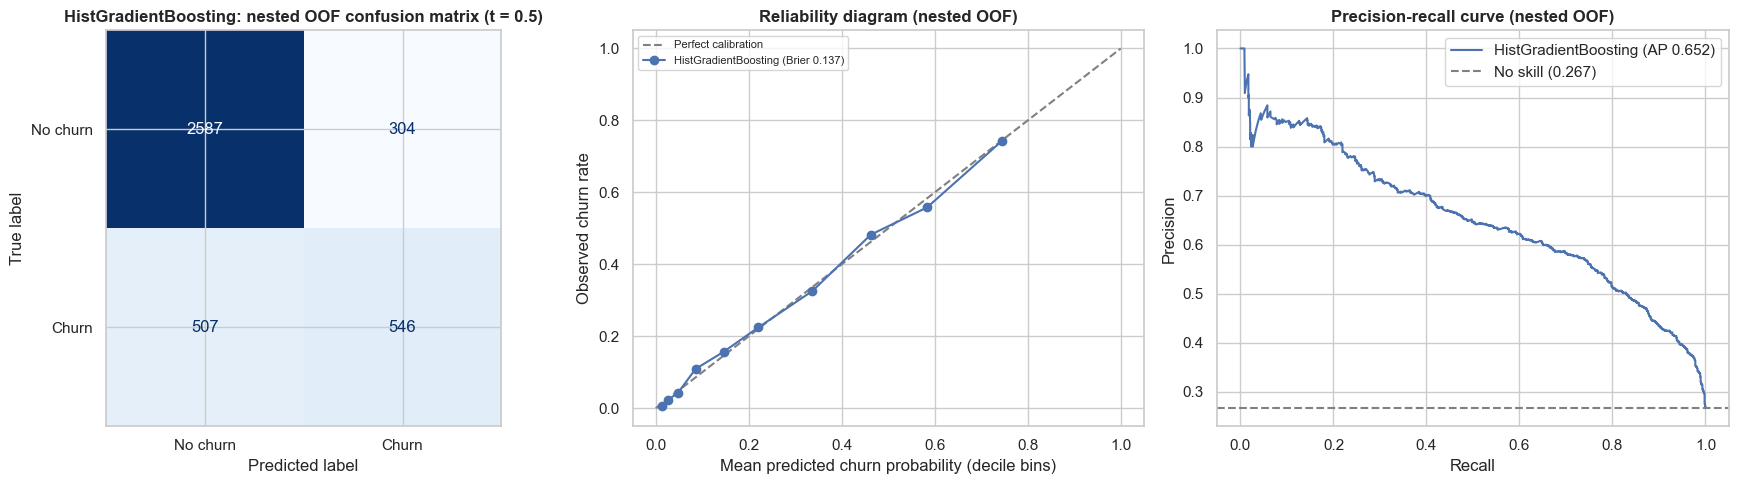

In [8]:
oof = nested["oof"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_confusion(axes[0], y_train, (oof >= 0.5).astype(int), f"{MODEL_NAME}: nested OOF confusion matrix (t = 0.5)")
plot_reliability(axes[1], y_train, {MODEL_NAME: oof}, "Reliability diagram (nested OOF)")
prec, rec, _ = precision_recall_curve(y_train, oof)
axes[2].plot(rec, prec, label=f"{MODEL_NAME} (AP {average_precision_score(y_train, oof):.3f})")
axes[2].axhline(y_train.mean(), linestyle="--", color="gray", label=f"No skill ({y_train.mean():.3f})")
axes[2].set_title("Precision-recall curve (nested OOF)")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
plt.tight_layout()
save_figure(fig, f"{SLUG}_diagnostics")
plt.show()

**Interpretation.**
- **At t = 0.5:** 546 churners caught, 507 missed, 304 non-churners flagged; similar to Logistic Regression.
- **Calibration** is good (Brier 0.137) because boosting directly minimises the log-loss.
- **Precision-recall curve** is close to the other ensembles' (pooled AP 0.652).

## 10. Model Interpretation

**Permutation importance** is the drop in PR-AUC when one original feature's values are shuffled. It is computed inside the nested CV, on each outer validation fold, for the model tuned and fitted without that fold, so it inherits no selection leakage. Shuffling one of two features that share information understates both. Importance describes what the *model* relies on; it is not a causal effect.

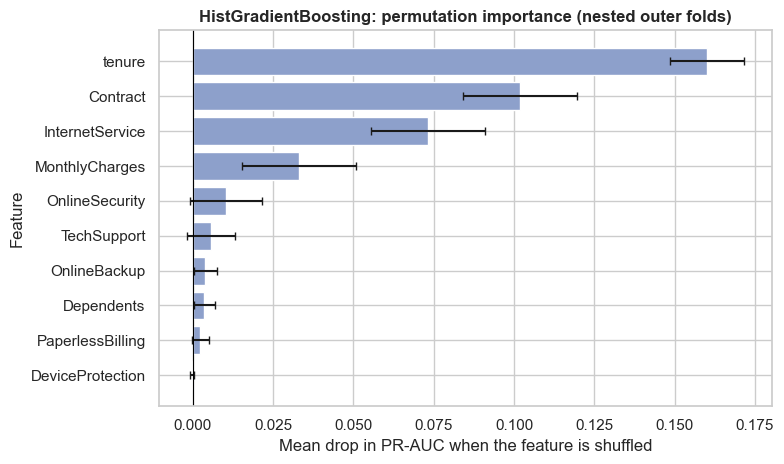

,mean,std
feature,,
tenure,0.1601,0.0116
Contract,0.1018,0.0178
InternetService,0.0731,0.0178
MonthlyCharges,0.0330,0.0178
OnlineSecurity,0.0104,0.0112
TechSupport,0.0057,0.0076
OnlineBackup,0.0039,0.0036
Dependents,0.0035,0.0033
PaperlessBilling,0.0024,0.0026


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.8))
perm_summary = plot_permutation_importance(ax, nested["importance"],
                                           f"{MODEL_NAME}: permutation importance (nested outer folds)")
plt.tight_layout()
save_figure(fig, f"{SLUG}_permutation_importance")
plt.show()
display(perm_summary.sort_values("mean", ascending=False).round(4))

**Interpretation.**
- `tenure` dominates (0.160), followed by `Contract` (0.102), `InternetService` (0.073) and `MonthlyCharges` (0.033). Add-ons contribute little and `DeviceProtection` nothing.
- The ranking agrees with the other models. The boosting model treats contract and service type as group splits rather than using price as a continuous gradient.

## 11. Strengths, Weaknesses and Conclusion

**Strengths**
- Well-calibrated probabilities.
- Fast.
- No extra dependency.

**Weaknesses**
- Nested PR-AUC 0.657, slightly below Logistic Regression.
- The most sensitive to hyperparameters of the scikit-learn models.
- Opaque.

**Conclusion:** boosting does not add predictive value on this dataset. The preference for tiny trees suggests the signal is largely additive. Notebooks 05 and 06 check whether two other boosting libraries reach the same conclusion.

### Saving the training-stage results

The nested OOF predictions, fold metrics, permutation importances and the final (training-set) pipeline are stored in `reports/cv_results/` for the comparison in notebook 08.

In [10]:
payload = {
    "name": MODEL_NAME, "slug": SLUG, "oof": nested["oof"], "folds": nested["folds"], "params": nested["params"],
    "importance": nested["importance"], "seconds": nested["seconds"], "baseline": baseline,
    "final_params": final_params, "final_search_score": search.best_score_,
    "final_train_score": search.cv_results_["mean_train_score"][search.best_index_],
    "final_pipeline": search.best_estimator_, "grid": PARAM_GRID, "prep_config": FINAL_PREP_CONFIG,
    "y_index": y_train.index.to_numpy(), "interpretability_rank": INTERPRETABILITY_RANK,
}
print("Saved:", save_results(SLUG, payload).relative_to(PROJECT_ROOT))

Saved: reports\cv_results\04_hist_gradient_boosting.joblib
